# Clase 4: Redes neuronales recurrentes

En las diapositivas vimos por qué importa el orden de las palabras y qué redes se propusieron para representarlo. Aquí las usamos como se usan en la práctica: un clasificador de texto comparado con un baseline, cómo elegir entre una red y TF-IDF, un etiquetador que da una salida por palabra y un traductor.

Al final hay dos ejercicios propuestos.

**Objetivos de la clase**

- Entrenar un clasificador recurrente en PyTorch de punta a punta y compararlo con un baseline TF-IDF.
- Elegir entre TF-IDF y una red recurrente según el puntaje, la cantidad de datos y el costo.
- Distinguir tres usos de una red recurrente: una salida por texto, una por palabra y una secuencia de salida.
- Explicar con un ejemplo por qué un encoder–decoder sin atención pierde calidad con oraciones largas.

## 0. Preparación

PyTorch, pandas y scikit-learn vienen instalados en Colab. Usamos las reseñas de Amazon de la clase 3. Los modelos ya entrenados, un etiquetador y un traductor, se descargan del repositorio del curso cuando se usan.

In [1]:
import random
import re
from collections import Counter
from collections.abc import Iterable
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 120)
torch.manual_seed(0)
URL_MODELOS = ("https://raw.githubusercontent.com/dccuchile/CC66Q/main/"
               "tutorials/modelos/")

In [2]:
URL = ("https://huggingface.co/datasets/mteb/amazon_reviews_multi/"
       "resolve/main/es/")
train = pd.read_json(URL + "train.jsonl", lines=True)
test = pd.read_json(URL + "test.jsonl", lines=True)
print("Dimensiones de train:", train.shape)
print("Dimensiones de test:", test.shape)

Dimensiones de train: (200000, 4)
Dimensiones de test: (5000, 4)


## 1. Un clasificador de reseñas, de punta a punta

Armemos el flujo completo con las reseñas de la clase 3: positiva si tiene 4 o 5 estrellas, negativa si tiene 1 o 2 (las de 3 quedan fuera). Para entrenar en pocos minutos usamos 20.000 reseñas de hasta 60 palabras. Separamos 2.000 para validación, con las que tomamos las decisiones; el conjunto de prueba queda para el final.

In [3]:
def tokenizar(texto: str) -> list[str]:
    """Devuelve las palabras en minúsculas."""
    return re.findall(r"\w+", texto.lower())


def preparar(df: pd.DataFrame) -> pd.DataFrame:
    """Deja las reseñas de 1 a 60 palabras con 1, 2, 4 o 5 estrellas.

    Parameters
    ----------
    df : pd.DataFrame
        Reseñas con las columnas `text` y `label` (de 0 a 4).

    Returns
    -------
    pd.DataFrame
        Las reseñas que quedan, con las columnas `tokens` y `positiva`.
    """
    df = df[df["label"] != 2].copy()  # las de 3 estrellas quedan fuera
    df["tokens"] = df["text"].map(tokenizar)
    df["positiva"] = (df["label"] >= 3).astype(int)  # 4 o 5 estrellas
    largo = df["tokens"].str.len()
    return df[largo.between(1, 60)]


resenas = preparar(train).sample(20_000, random_state=0)
validacion = resenas[:2_000]
entreno = resenas[2_000:]
prueba = preparar(test)

proporcion_positivas = round(entreno["positiva"].mean(), 2)
print("Reseñas de entrenamiento:", len(entreno))
print("Reseñas de validación:", len(validacion))
print("Reseñas de prueba:", len(prueba))
print("Proporción de positivas en entrenamiento:", proporcion_positivas)

Reseñas de entrenamiento: 18000
Reseñas de validación: 2000
Reseñas de prueba: 3644
Proporción de positivas en entrenamiento: 0.51


### 1.1 Primero, un baseline

Antes de entrenar una red conviene saber qué puntaje se logra sin ella. Usamos TF-IDF, de la clase 2, con regresión logística, que se entrena en segundos. Probamos también TF-IDF con bigramas, que capturan algo del orden.

In [4]:
tfidf = TfidfVectorizer(min_df=2)
X_entreno_tfidf = tfidf.fit_transform(entreno["text"])
logistica = LogisticRegression(max_iter=2000)
logistica.fit(X_entreno_tfidf, entreno["positiva"])

tfidf_bigramas = TfidfVectorizer(min_df=2, ngram_range=(1, 2))
X_entreno_bigramas = tfidf_bigramas.fit_transform(entreno["text"])
logistica_bigramas = LogisticRegression(max_iter=2000)
logistica_bigramas.fit(X_entreno_bigramas, entreno["positiva"])

X_val_tfidf = tfidf.transform(validacion["text"])
X_val_bigramas = tfidf_bigramas.transform(validacion["text"])
accuracies_val = pd.Series({
    "TF-IDF": logistica.score(X_val_tfidf, validacion["positiva"]),
    "TF-IDF con bigramas": logistica_bigramas.score(
        X_val_bigramas, validacion["positiva"]),
}, name="accuracy de validación")
display(accuracies_val)

TF-IDF                 0.91
TF-IDF con bigramas    0.91
Name: accuracy de validación, dtype: float64

### 1.2 Del texto a tensores

Ese es el puntaje que la red tiene que superar. Para entrenarla, el texto tiene que pasar a números: cada palabra del vocabulario recibe un id, y `nn.Embedding` busca su vector. El 0 queda para el relleno y el 1 para las palabras fuera del vocabulario. En la clase 3 usamos embeddings ya entrenados; aquí la tabla parte al azar y se aprende junto con el resto.

In [5]:
def crear_vocabulario(listas: Iterable[list[str]],
                      minimo: int = 3) -> dict[str, int]:
    """Asigna un id a cada palabra que aparece al menos `minimo` veces.

    Parameters
    ----------
    listas : Iterable[list[str]]
        Los tokens de cada documento.
    minimo : int
        Cantidad mínima de apariciones para entrar al vocabulario.

    Returns
    -------
    dict[str, int]
        Id de cada palabra; 0 es el relleno y 1 las palabras desconocidas.
    """
    frecuencias = Counter()
    for tokens in listas:
        frecuencias.update(tokens)
    vocab = {"<pad>": 0, "<unk>": 1}
    for palabra, veces in frecuencias.most_common():
        if veces >= minimo:
            vocab[palabra] = len(vocab)
    return vocab


vocab = crear_vocabulario(entreno["tokens"])
print("Palabras en el vocabulario:", len(vocab))

Palabras en el vocabulario: 7583


In [6]:
# los datos de un conjunto: ids con relleno, largos reales y etiquetas
Datos = tuple[torch.Tensor, torch.Tensor, torch.Tensor]


def codificar(tokens: list[str],
              vocab: dict[str, int] = vocab) -> torch.Tensor:
    """Convierte los tokens en ids; 1 para los desconocidos.

    Parameters
    ----------
    tokens : list[str]
        Las palabras de un texto.
    vocab : dict[str, int]
        Id de cada palabra conocida.

    Returns
    -------
    torch.Tensor
        Ids de los tokens, con forma (largo,).
    """
    ids = [vocab.get(palabra, 1) for palabra in tokens]
    return torch.tensor(ids)


def lote(df: pd.DataFrame, etiqueta: str = "positiva",
         vocab: dict[str, int] = vocab) -> Datos:
    """Arma la matriz de ids con relleno, los largos y las etiquetas.

    Parameters
    ----------
    df : pd.DataFrame
        Textos, con la columna `tokens` y la de las etiquetas.
    etiqueta : str
        Nombre de la columna con la clase de cada texto.
    vocab : dict[str, int]
        Id de cada palabra conocida.

    Returns
    -------
    Datos
        Ids con relleno (textos, largo), largos reales (textos,) y
        etiquetas (textos,).
    """
    secuencias = [codificar(tokens, vocab) for tokens in df["tokens"]]
    # relleno con ceros hasta el largo de la reseña más larga
    X = nn.utils.rnn.pad_sequence(secuencias, batch_first=True)
    largos = torch.tensor(df["tokens"].str.len().values)
    etiquetas = torch.tensor(df[etiqueta].values)
    return X, largos, etiquetas


datos_entreno = lote(entreno)
datos_val = lote(validacion)
datos_prueba = lote(prueba)

ids_entreno = datos_entreno[0]
print("Forma de la matriz de ids:", ids_entreno.shape)
print("Primeros 12 ids de la primera reseña:", ids_entreno[0, :12])

Forma de la matriz de ids: torch.Size([18000, 60])
Primeros 12 ids de la primera reseña: tensor([  18,    8, 1198,    7, 2882,    6,   83,  135,   60,  763,   13, 1519])


Las reseñas cortas se rellenan con ceros hasta el largo de la más larga.

**Antes de ejecutar:** si a una reseña le agregamos ceros de relleno al final, ¿cambia el último estado de una GRU?

In [7]:
torch.manual_seed(0)
gru = nn.GRU(8, 8, batch_first=True)
embedding = nn.Embedding(len(vocab), 8, padding_idx=0)

ids = codificar(tokenizar("El producto llegó roto"))
relleno = torch.zeros(5, dtype=torch.long)  # cinco ceros al final
ids_con_relleno = torch.cat([ids, relleno])
largo_real = torch.tensor([len(ids)])

with torch.no_grad():
    _, h_sin = gru(embedding(ids[None]))
    vectores = embedding(ids_con_relleno[None])
    _, h_con = gru(vectores)
    # con pack_padded_sequence la red no ve el relleno
    empacados = nn.utils.rnn.pack_padded_sequence(
        vectores, largo_real, batch_first=True)
    _, h_empacado = gru(empacados)

dif_con_relleno = (h_con - h_sin).norm().item()
dif_empacado = (h_empacado - h_sin).norm().item()
print("Diferencia del estado con relleno:", dif_con_relleno)
print("Diferencia con pack_padded_sequence:", dif_empacado)

Diferencia del estado con relleno: 0.7389665842056274
Diferencia con pack_padded_sequence: 0.0


Cambia. La GRU actualiza el estado también en el relleno, así que el «último estado» es el del último cero, no el de la última palabra. `pack_padded_sequence` le pasa a la red el largo real de cada reseña, y el estado final vuelve a ser el de la última palabra. Por eso guardamos los largos.

El modelo tiene tres capas: la tabla de embeddings, la GRU y una capa lineal que convierte el último estado en dos puntajes, uno por clase.

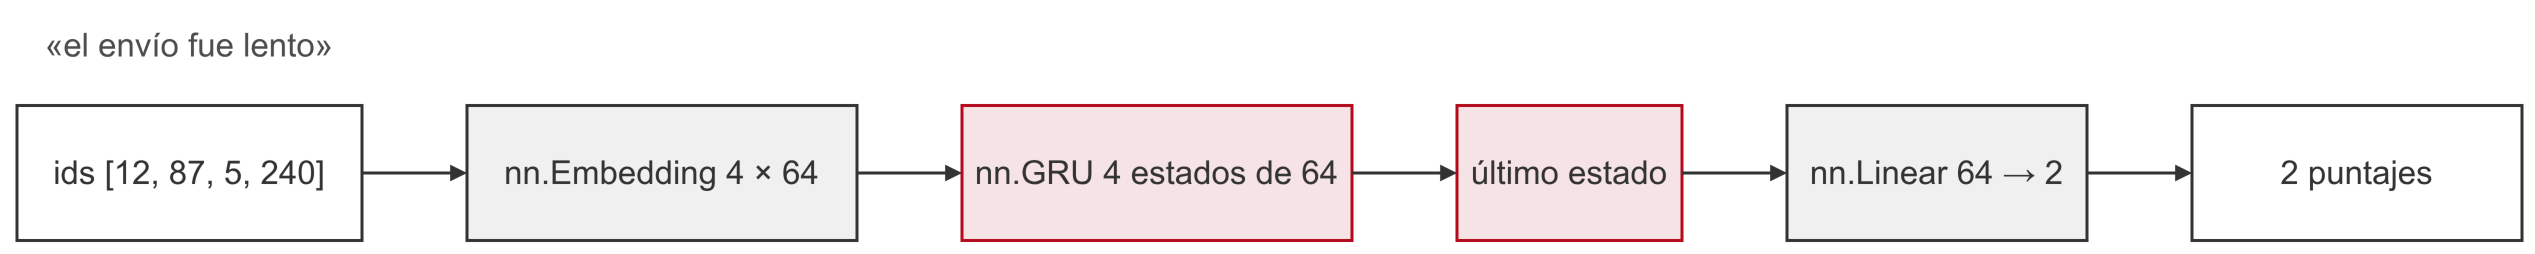

In [8]:
class Clasificador(nn.Module):
    """Embeddings, red recurrente y capa lineal sobre el último estado."""

    def __init__(self, n_palabras: int, celda: type[nn.Module] = nn.GRU,
                 dim_embedding: int = 64, dim_estado: int = 64,
                 salidas: int = 2) -> None:
        super().__init__()
        self.embedding = nn.Embedding(n_palabras, dim_embedding, padding_idx=0)
        self.recurrente = celda(dim_embedding, dim_estado, batch_first=True)
        self.salida = nn.Linear(dim_estado, salidas)

    def forward(self, X: torch.Tensor,
                largos: torch.Tensor) -> torch.Tensor:
        """X: (lote, largo), largos: (lote,); devuelve (lote, salidas)."""
        vectores = self.embedding(X)
        empacados = nn.utils.rnn.pack_padded_sequence(
            vectores, largos, batch_first=True, enforce_sorted=False)
        _, h = self.recurrente(empacados)  # h: el último estado
        if isinstance(h, tuple):  # la LSTM devuelve (estado, memoria)
            h = h[0]
        return self.salida(h[-1])

El ciclo de entrenamiento es el del módulo de deep learning: lotes de 64 reseñas, entropía cruzada y Adam. Después de cada epoch medimos la accuracy en validación y guardamos los pesos de la mejor epoch, una forma simple de detención temprana (early stopping). Las tres epochs tardan un par de minutos en CPU. Si ya existe `clasificador_resenas.pt` (se guarda al entrenar y en la sección 1.5), la celda carga esos pesos y no entrena.

In [9]:
def accuracy(modelo: nn.Module, datos: Datos) -> float:
    """Calcula la fracción de aciertos del modelo en los datos.

    Parameters
    ----------
    modelo : nn.Module
        Clasificador que se llama como `modelo(X, largos)`.
    datos : Datos
        Ids con relleno, largos y etiquetas, como los arma `lote`.

    Returns
    -------
    float
        Fracción de textos bien clasificados.
    """
    X, largos, etiquetas = datos
    modelo.eval()
    with torch.no_grad():
        predicciones = modelo(X, largos).argmax(1)
    return (predicciones == etiquetas).float().mean().item()


def entrenar(modelo: nn.Module, datos_entreno: Datos, datos_val: Datos,
             epochs: int = 3) -> nn.Module:
    """Entrena el modelo y deja los pesos de su mejor epoch en validación.

    Parameters
    ----------
    modelo : nn.Module
        Clasificador que se llama como `modelo(X, largos)`.
    datos_entreno : Datos
        Ids con relleno, largos y etiquetas de entrenamiento.
    datos_val : Datos
        Los mismos tres tensores para validación.
    epochs : int
        Cantidad de pasadas por los datos de entrenamiento.

    Returns
    -------
    nn.Module
        El mismo modelo, con los pesos de la epoch de mayor accuracy.
    """
    X, largos, etiquetas = datos_entreno
    optimizador = torch.optim.Adam(modelo.parameters(), lr=2e-3)
    perdida = nn.CrossEntropyLoss()
    mejor_accuracy = 0
    for epoch in range(epochs):
        modelo.train()
        orden = torch.randperm(len(X))  # reseñas en orden al azar
        for indices in orden.split(64):  # lotes de 64
            optimizador.zero_grad()
            puntajes = modelo(X[indices], largos[indices])
            error = perdida(puntajes, etiquetas[indices])
            error.backward()
            optimizador.step()
        acc = accuracy(modelo, datos_val)
        print(f"epoch {epoch + 1}: accuracy de validación {acc:.3f}")
        if acc > mejor_accuracy:
            mejor_accuracy = acc
            mejores_pesos = {}  # copia de los pesos de la mejor epoch
            for nombre, tensor in modelo.state_dict().items():
                mejores_pesos[nombre] = tensor.clone()
    modelo.load_state_dict(mejores_pesos)
    return modelo


archivo_modelo = Path("clasificador_resenas.pt")

torch.manual_seed(0)
modelo = Clasificador(len(vocab))
if archivo_modelo.exists():
    guardado = torch.load(archivo_modelo)
    if guardado["vocab"] != vocab:
        raise ValueError("El vocabulario guardado no es el de este notebook")
    modelo.load_state_dict(guardado["pesos"])
    modelo.eval()
    print("Pesos cargados de clasificador_resenas.pt; "
          "se omite el entrenamiento")
else:
    modelo = entrenar(modelo, datos_entreno, datos_val)
    torch.save({"pesos": modelo.state_dict(), "vocab": vocab}, archivo_modelo)

epoch 1: accuracy de validación 0.891


epoch 2: accuracy de validación 0.899


epoch 3: accuracy de validación 0.904


### 1.3 Evaluación

Recién ahora usamos el conjunto de prueba, una sola vez, para los tres modelos.

**Antes de ejecutar:** ¿supera la GRU al baseline?

In [10]:
X_prueba_tfidf = tfidf.transform(prueba["text"])
X_prueba_bigramas = tfidf_bigramas.transform(prueba["text"])
accuracies_prueba = pd.Series({
    "TF-IDF": logistica.score(X_prueba_tfidf, prueba["positiva"]),
    "TF-IDF con bigramas": logistica_bigramas.score(
        X_prueba_bigramas, prueba["positiva"]),
    "GRU": accuracy(modelo, datos_prueba),
}, name="accuracy de prueba")
display(accuracies_prueba.round(3))

TF-IDF                 0.92
TF-IDF con bigramas    0.92
GRU                    0.92
Name: accuracy de prueba, dtype: float64

Los tres llegan a 0,92: con estas reseñas, la GRU no supera al baseline. El puntaje no dice dónde se equivoca. La matriz de confusión cuenta los aciertos y errores de cada clase; después miramos los errores en que la GRU estaba más segura.

In [11]:
X, largos, _ = datos_prueba
with torch.no_grad():
    puntajes = modelo(X, largos)
p_positiva = torch.softmax(puntajes, 1)[:, 1].numpy()
resultado = prueba.assign(p_positiva=p_positiva)

predice_positiva = resultado["p_positiva"] > 0.5
matriz_confusion = pd.crosstab(
    resultado["positiva"], predice_positiva,
    rownames=["real"], colnames=["predice positiva"])
display(matriz_confusion)

predice positiva,False,True
real,,
0,1600,185
1,118,1741


In [12]:
predice_positiva = resultado["p_positiva"] > 0.5
es_positiva = resultado["positiva"] == 1
acierto = predice_positiva == es_positiva
errores = resultado[~acierto]

# los errores en que la GRU estaba más segura: lejos de 0,5
confianza = (errores["p_positiva"] - 0.5).abs()
mas_seguros = confianza.nlargest(5).index
display(errores.loc[mas_seguros, ["text", "positiva", "p_positiva"]])

,text,positiva,p_positiva
1733,"Buena calidad, falla la talla\n\nTallaje un poco grande, compré una L que es mi talla y me sobra de cintura. Por lo ...",0,9.99e-01
3939,"Producto bien, embalaje mal, muy mal.\n\nEl producto en sí bien porque ya tenía otro y se de qué va el tema, pero mu...",1,3.98e-03
3144,No están mal.\n\nEs un producto que da lo que vale. A mí me costaron 30 en su momento y tampoco se pueden esperar mi...,1,5.76e-03
1421,"Grosor fino\n\nEl producto es tal cual, aunque con un grosor inferior al esperado, pero es util",0,9.93e-01
1076,El producto es bueno Adactador coriente falla\n\nFalla el adaptador de corriente Reiniciándose muy seguido,0,9.93e-01


Los errores más seguros son reseñas mixtas: «Buena calidad, falla la talla» tiene 1 o 2 estrellas y la GRU la da por positiva. En «No están mal», la negación da vuelta el sentido de «mal». En otras, las estrellas no coinciden con el título. Mirar los errores ayuda a decidir qué hacer: conseguir más ejemplos de ese tipo, cambiar de modelo o aceptar que la tarea tiene un techo.

### 1.4 El orden

Dos reseñas con las mismas palabras en otro orden; el veredicto está después de «pero». Para TF-IDF con unigramas son el mismo vector.

**Antes de ejecutar:** ¿la GRU les da el mismo puntaje?

In [13]:
def predecir(texto: str) -> tuple[float, float]:
    """Estima P(positiva) de una reseña y cuántas palabras conoce el modelo.

    Parameters
    ----------
    texto : str
        Reseña escrita por una persona.

    Returns
    -------
    tuple[float, float]
        Probabilidad de reseña positiva y fracción de palabras que están
        en el vocabulario, ambas redondeadas a 2 decimales.
    """
    tokens = tokenizar(texto)
    ids = codificar(tokens)[None]  # un lote de una reseña
    largo = torch.tensor([len(tokens)])
    modelo.eval()
    with torch.no_grad():
        probabilidades = torch.softmax(modelo(ids, largo), 1)
    p_positiva = probabilidades[0, 1]
    conocidas = [palabra in vocab for palabra in tokens]
    fraccion_conocidas = sum(conocidas) / len(tokens)
    return round(p_positiva.item(), 2), round(fraccion_conocidas, 2)


par_pero = ["El envío fue lento, pero el producto es excelente",
            "El producto es excelente, pero el envío fue lento"]
for resena in par_pero:
    X_resena = tfidf.transform([resena])
    p_tfidf = logistica.predict_proba(X_resena)[0, 1].round(2)
    print(predecir(resena), p_tfidf, resena)

(0.94, 1.0) 0.43 El envío fue lento, pero el producto es excelente
(0.78, 1.0) 0.43 El producto es excelente, pero el envío fue lento


TF-IDF les da el mismo número. La GRU les da números distintos y prefiere la que termina con «excelente».

La GRU calcula un estado después de cada palabra. Si le aplicamos la capa de salida a cada uno, vemos qué diría el modelo si la reseña terminara ahí.

**Antes de ejecutar:** en «El envío fue lento, pero el producto es excelente», ¿en qué palabra cambia de opinión?

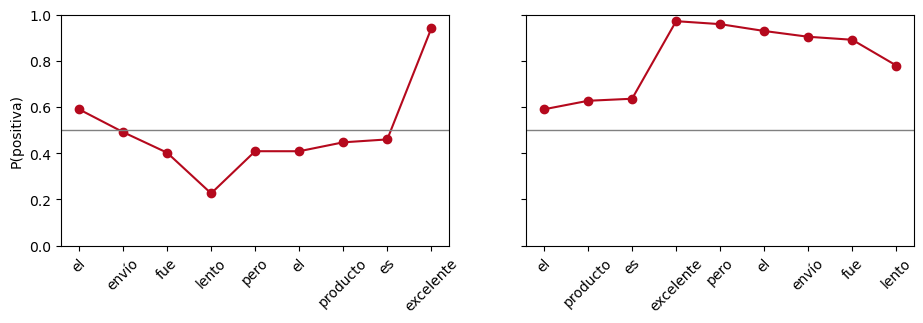

In [14]:
def lectura(texto: str) -> pd.Series:
    """Calcula P(positiva) si la reseña terminara en cada palabra.

    Parameters
    ----------
    texto : str
        Reseña escrita por una persona.

    Returns
    -------
    pd.Series
        Probabilidad de reseña positiva, con las palabras como índice.
    """
    tokens = tokenizar(texto)
    ids = codificar(tokens)[None]
    with torch.no_grad():
        vectores = modelo.embedding(ids)
        estados, _ = modelo.recurrente(vectores)  # un estado por palabra
        puntajes = modelo.salida(estados[0])
        p_positiva = torch.softmax(puntajes, 1)[:, 1]
    return pd.Series(p_positiva.numpy(), index=tokens)


fig, ejes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for eje, texto in zip(ejes, par_pero):
    p_positiva = lectura(texto)
    posiciones = range(len(p_positiva))
    eje.plot(posiciones, p_positiva.values, marker="o", color="#B5091D")
    eje.set_xticks(posiciones, p_positiva.index, rotation=45)
    eje.axhline(0.5, color="#808080", lw=1)
ejes[0].set_ylabel("P(positiva)")
ejes[0].set_ylim(0, 1);

La probabilidad baja con «lento» y sube con «excelente»; en la otra reseña, al revés. En las dos pesa más la última cláusula, aunque ambas quedan sobre 0,5. El modelo usa el orden, aunque eso no significa que entienda la oración. Prueben con «No es malo» o con una negación larga.

Ahora una reseña escrita en el chat. La segunda línea es la fracción de sus palabras que el modelo conoce; las desconocidas no aportan nada.

In [15]:
resena = ("Llegó en dos días y la calidad es mejor de lo que esperaba "
          "por ese precio")

probabilidad, fraccion_conocidas = predecir(resena)
print("Probabilidad de positiva:", probabilidad)
print("Fracción de palabras conocidas:", fraccion_conocidas)

Probabilidad de positiva: 0.18
Fracción de palabras conocidas: 1.0


Esta reseña positiva sale 0,18: el modelo se equivoca, aunque conoce todas sus palabras.

### 1.5 Guardar el modelo y usarlo

Para usar el modelo fuera de este notebook hay que guardar los pesos y el vocabulario: sin la tabla palabra → id, los pesos no sirven. Al predecir, `eval()` apaga lo que solo se usa al entrenar, como el dropout, y `torch.inference_mode()` no guarda lo que hace falta para el gradiente.

In [16]:
torch.save({"pesos": modelo.state_dict(), "vocab": vocab},
           "clasificador_resenas.pt")

guardado = torch.load("clasificador_resenas.pt")
cargado = Clasificador(len(guardado["vocab"]))
cargado.load_state_dict(guardado["pesos"])
cargado.eval()
with torch.inference_mode():
    ids = codificar(tokenizar("No funciona, lo devolví"), guardado["vocab"])
    puntajes = cargado(ids[None], torch.tensor([len(ids)]))
    print(torch.softmax(puntajes, 1))

tensor([[0.9819, 0.0181]])


## 2. ¿Qué red y cuándo?

En la práctica se usa una GRU o una LSTM. En nuestro clasificador se cambia con un argumento: `Clasificador(len(vocab), nn.LSTM)`. En cada paso, la LSTM calcula cuatro bloques (forget gate, input gate, output gate y candidato) y la GRU, tres (update gate, reset gate y candidato). Comparemos su tamaño, sin entrenar la LSTM:

In [ ]:
def contar_parametros(red: nn.Module) -> int:
    """Cuenta los parámetros de una red o de una de sus capas."""
    return sum(parametro.numel() for parametro in red.parameters())


modelo_lstm = Clasificador(len(vocab), nn.LSTM)
for nombre, red in [("GRU", modelo), ("LSTM", modelo_lstm)]:
    print(f"{nombre}: embeddings {contar_parametros(red.embedding)}, "
          f"capa recurrente {contar_parametros(red.recurrente)}, "
          f"total {contar_parametros(red)}")

GRU: embeddings 485312, capa recurrente 24960, total 510402
LSTM: embeddings 485312, capa recurrente 33280, total 518722


La capa recurrente de la LSTM tiene un tercio más de parámetros que la de la GRU: cuatro bloques contra tres. En los dos modelos, casi todos los parámetros están en la tabla de embeddings.

Además del puntaje, en un sistema real importan el tamaño del modelo y cuánto tarda en predecir. Comparemos la GRU con TF-IDF en las reseñas de prueba. Una sola medición de tiempo varía mucho, así que `%timeit` la repite y `.best` es la más rápida.

In [17]:
t_gru = %timeit -o -q -n 1 -r 3 accuracy(modelo, datos_prueba)
textos = prueba["text"]
t_tfidf = %timeit -o -q -n 1 -r 3 logistica.predict(tfidf.transform(textos))

parametros_gru = sum(parametro.numel() for parametro in modelo.parameters())
parametros_logistica = logistica.coef_.size + 1  # coeficientes y sesgo
comparacion = pd.DataFrame({
    "parámetros": [parametros_gru, parametros_logistica],
    "segundos para predecir la prueba": [t_gru.best, t_tfidf.best],
}, index=["GRU", "TF-IDF"])
display(comparacion)

,parámetros,segundos para predecir la prueba
GRU,510402,0.04
TF-IDF,10108,0.02


La GRU tiene unas 50 veces más parámetros que la regresión logística y tarda más en predecir las 3.644 reseñas de prueba, aun sin contar la tokenización. También tardó más en entrenar: minutos, contra segundos. Con el mismo puntaje, en un sistema real convendría TF-IDF, que es más chico y más rápido.

La red recurrente se justifica cuando el orden cambia la respuesta, como en el par con «pero», y hay datos suficientes. Desde la clase 5, la opción habitual es partir de un modelo preentrenado.

### Con pocos datos

Con los tweets de la Tarea 1 (odio, incivilidad y normal; unos 12.000) el resultado se da vuelta. Este es el resultado del ejercicio 2, con la misma GRU y la misma partición para los dos modelos:

| | accuracy | macro-F1 |
|---|---|---|
| GRU | 0,74 | 0,72 |
| TF-IDF | 0,77 | 0,75 |

Las clases no están balanceadas, así que miramos también macro-F1: el promedio del F1 de cada clase, en el que «odio», la menos frecuente, pesa lo mismo que las otras. Aquí la GRU entrenada desde cero perdió. Una explicación posible: con unos 9.000 tweets de entrenamiento hay pocos ejemplos de cada palabra para aprender su vector, y TF-IDF no necesita aprenderlo.

## 3. Una salida por palabra

Para clasificar usamos solo el último estado. Si usamos todos, la red da una salida por palabra: su categoría gramatical, por ejemplo, o si es parte del nombre de una persona, una organización o un lugar (reconocimiento de entidades, named entity recognition o NER). Para etiquetar una palabra ayudan también las que vienen después, así que se usa una red bidireccional (bidirectional): lee la oración en los dos sentidos y junta los dos estados de cada palabra.

Descarguemos los pesos del modelo ya entrenado desde el repositorio del curso. Se entrenó con las 14.186 oraciones del corpus Spanish-GSD de Universal Dependencies (licencia CC BY-SA 4.0), etiquetadas a mano.

In [18]:
class Etiquetador(nn.Module):
    """GRU bidireccional que da una categoría por palabra."""

    def __init__(self, n_palabras: int, n_categorias: int,
                 dim_embedding: int = 64, dim_estado: int = 64) -> None:
        super().__init__()
        self.embedding = nn.Embedding(n_palabras, dim_embedding, padding_idx=0)
        self.recurrente = nn.GRU(dim_embedding, dim_estado, batch_first=True,
                                 bidirectional=True)
        self.salida = nn.Linear(2 * dim_estado, n_categorias)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        """X: (lote, largo); devuelve (lote, largo, categorías)."""
        vectores = self.embedding(X)
        estados, _ = self.recurrente(vectores)
        return self.salida(estados)  # una salida por palabra


guardado = torch.hub.load_state_dict_from_url(
    URL_MODELOS + "4-etiquetador-ud.pt", weights_only=True)
vocab_ud = {palabra: i for i, palabra in enumerate(guardado["vocab"])}
categorias = guardado["categorias"]
etiquetador = Etiquetador(len(vocab_ud), len(categorias),
                          guardado["d"], guardado["h"])
pesos = {nombre: tensor.float()  # los pesos vienen en fp16
         for nombre, tensor in guardado["pesos"].items()}
etiquetador.load_state_dict(pesos)
etiquetador.eval()
print("Categorías:", categorias[1:])

Categorías: ['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ', 'NOUN', 'NUM', 'PART', 'PRON', 'PROPN', 'PUNCT', 'SCONJ', 'SYM', 'VERB', 'X']


**Antes de ejecutar:** ¿qué categoría le da al primer «vino» de «Vino ayer y trajo vino»? ¿Y al segundo?

In [19]:
def etiquetar(texto: str) -> pd.Series:
    """Asigna una categoría gramatical a cada palabra.

    Parameters
    ----------
    texto : str
        Una oración.

    Returns
    -------
    pd.Series
        Categoría de cada palabra, con las palabras como índice.
    """
    tokens = tokenizar(texto)
    ids = codificar(tokens, vocab_ud)[None]
    with torch.no_grad():
        puntajes = etiquetador(ids)
    ids_categorias = puntajes.argmax(-1)[0]
    nombres = [categorias[i] for i in ids_categorias.tolist()]
    return pd.Series(nombres, index=tokens)


oraciones = ["Vino ayer y trajo vino", "El vino estaba frío",
             "Llama a tu madre"]
for oracion in oraciones:
    etiquetas = etiquetar(oracion)
    pares = [f"{palabra}/{categoria}"
             for palabra, categoria in etiquetas.items()]
    print(" ".join(pares))

vino/VERB ayer/ADV y/CCONJ trajo/AUX vino/NOUN
el/DET vino/NOUN estaba/AUX frío/ADJ
llama/VERB a/ADP tu/DET madre/NOUN


El primer «vino» es verbo (VERB) y el último, sustantivo (NOUN): la misma palabra, con el mismo embedding, recibe etiquetas distintas según sus vecinas. Las otras etiquetas: AUX verbo auxiliar, ADP preposición, DET determinante. Como la red es bidireccional, necesita la oración completa antes de etiquetar; una que lee solo hacia adelante puede etiquetar el texto a medida que llega.

## 4. Una secuencia de otro largo: encoder–decoder

Clasificar da una salida por texto y etiquetar, una por palabra. Traducir pide una salida de otro largo. El encoder–decoder (Sutskever et al., 2014; Cho et al., 2014) usa dos redes recurrentes. El encoder lee la entrada, y su último estado es lo único que recibe el decoder, que escribe la salida símbolo por símbolo.

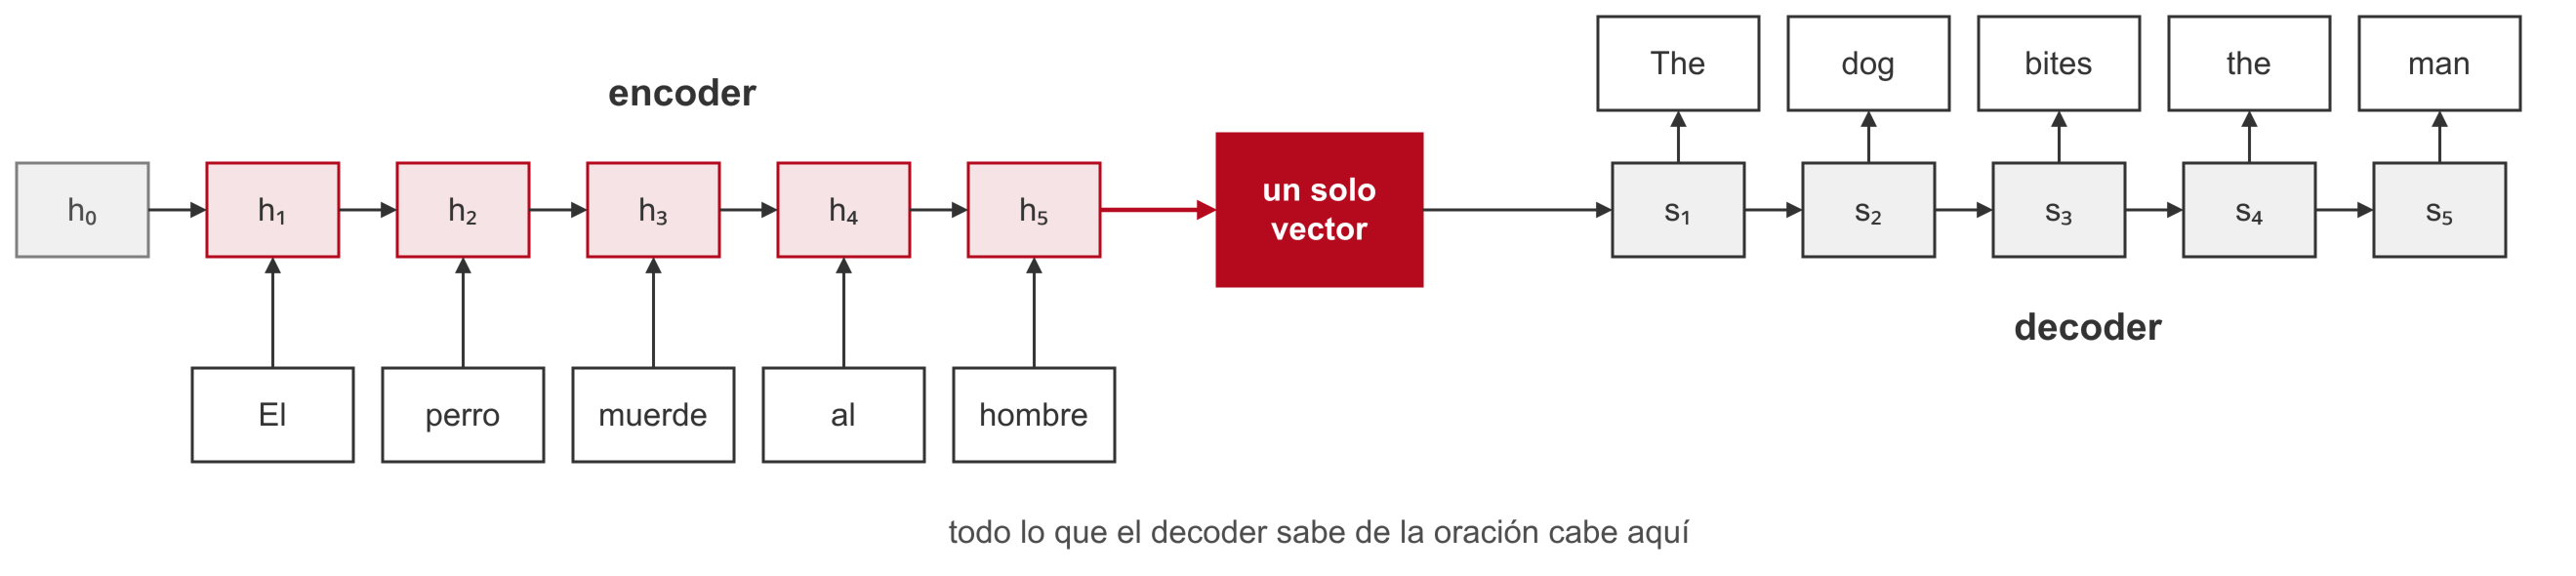

Probemos primero con un problema que podemos entrenar aquí: pasar números escritos en palabras a dígitos. «dos mil veintiséis» son tres palabras y «2026» son cuatro dígitos.

In [20]:
UNIDADES = (
    "cero uno dos tres cuatro cinco seis siete ocho nueve diez once doce "
    "trece catorce quince dieciséis diecisiete dieciocho diecinueve veinte "
    "veintiuno veintidós veintitrés veinticuatro veinticinco veintiséis "
    "veintisiete veintiocho veintinueve").split()
DECENAS = (
    "_ _ _ treinta cuarenta cincuenta sesenta setenta ochenta noventa"
).split()
CENTENAS = (
    "_ ciento doscientos trescientos cuatrocientos quinientos seiscientos "
    "setecientos ochocientos novecientos").split()


def hasta_mil(n: int) -> list[str]:
    """Escribe en palabras un número entre 1 y 999.

    Parameters
    ----------
    n : int
        Número entre 1 y 999.

    Returns
    -------
    list[str]
        Las palabras del número.
    """
    if n == 100:
        return ["cien"]
    palabras = []
    if n >= 100:
        palabras.append(CENTENAS[n // 100])
    n %= 100
    if 0 < n < 30:
        palabras.append(UNIDADES[n])
    elif n >= 30:
        palabras.append(DECENAS[n // 10])
        if n % 10:
            palabras += ["y", UNIDADES[n % 10]]
    return palabras


def en_palabras(n: int) -> list[str]:
    """Escribe en palabras un número entre 0 y 9.999.999.

    Parameters
    ----------
    n : int
        Número entre 0 y 9.999.999.

    Returns
    -------
    list[str]
        Las palabras del número.
    """
    if n == 0:
        return ["cero"]
    millones = n // 10**6
    miles = n // 1000 % 1000
    resto = n % 1000
    apocope = {"uno": "un", "veintiuno": "veintiún"}  # un mil, veintiún mil
    palabras = []
    if millones:
        if millones == 1:
            palabras += ["un", "millón"]
        else:
            palabras += hasta_mil(millones) + ["millones"]
    if miles:
        if miles == 1:
            palabras += ["mil"]
        else:
            antes_de_mil = [apocope.get(p, p) for p in hasta_mil(miles)]
            palabras += antes_de_mil + ["mil"]
    if resto:
        palabras += hasta_mil(resto)
    return palabras


for n in [16, 342, 2026, 21_000, 1_200_000]:
    print(n, " ".join(en_palabras(n)))

16 dieciséis
342 trescientos cuarenta y dos
2026 dos mil veintiséis
21000 veintiún mil
1200000 un millón doscientos mil


In [21]:
def numero_al_azar() -> int:
    """Elige un número con una cantidad de dígitos al azar entre 1 y 7.

    Returns
    -------
    int
        Número entre 0 y 9.999.999.
    """
    cantidad_digitos = random.randint(1, 7)
    if cantidad_digitos > 1:
        minimo = 10 ** (cantidad_digitos - 1)
    else:
        minimo = 0
    maximo = 10**cantidad_digitos - 1
    return random.randint(minimo, maximo)


random.seed(0)
numeros_distintos = {numero_al_azar() for _ in range(45_000)}
numeros = list(numeros_distintos)
random.shuffle(numeros)
numeros_prueba = numeros[:2_000]
numeros_entreno = numeros[2_000:]
pares_prueba = [(en_palabras(n), str(n)) for n in numeros_prueba]
pares_entreno = [(en_palabras(n), str(n)) for n in numeros_entreno]

# vocabulario de entrada: las palabras que aparecen al entrenar
palabras_vistas = set()
for palabras, _ in pares_entreno:
    palabras_vistas.update(palabras)
palabras_num = ["<pad>"] + sorted(palabras_vistas)
id_palabra = {palabra: i for i, palabra in enumerate(palabras_num)}
simbolos = ["<pad>", "<s>", "</s>"] + list("0123456789")


def lote_numeros(
        pares: list[tuple[list[str], str]]
) -> tuple[torch.Tensor, torch.Tensor]:
    """Pasa las palabras a ids y los dígitos a ids, con inicio y fin.

    Parameters
    ----------
    pares : list[tuple[list[str], str]]
        Pares (número en palabras, número en dígitos).

    Returns
    -------
    X : torch.Tensor
        Ids de las palabras con relleno, forma (pares, palabras).
    Y : torch.Tensor
        Ids de `<s>`, los dígitos y `</s>` con relleno, forma
        (pares, dígitos + 2).
    """
    entradas = []
    salidas = []
    for palabras, digitos in pares:
        ids_palabras = [id_palabra[palabra] for palabra in palabras]
        ids_digitos = [simbolos.index(digito) for digito in digitos]
        entradas.append(torch.tensor(ids_palabras))
        salidas.append(torch.tensor([1] + ids_digitos + [2]))  # <s> ... </s>
    X = nn.utils.rnn.pad_sequence(entradas, batch_first=True)
    Y = nn.utils.rnn.pad_sequence(salidas, batch_first=True)
    return X, Y


print("Pares de entrenamiento:", len(pares_entreno))
print("Primer par:", pares_entreno[0])

Pares de entrenamiento: 22527
Primer par: (['dieciséis', 'mil', 'ciento', 'setenta', 'y', 'ocho'], '16178')


El modelo son dos GRU. Al entrenar, el decoder recibe en cada paso el dígito anterior correcto, no el que predijo: es el *teacher forcing*. Si ya existe `encoder_decoder_numeros.pt`, la celda carga esos pesos y no entrena.

In [22]:
class EncoderDecoder(nn.Module):
    """Dos GRU: el encoder lee la entrada y el decoder escribe la salida."""

    def __init__(self, n_origen: int, n_destino: int,
                 dim_embedding: int = 64, dim_estado: int = 128) -> None:
        super().__init__()
        self.emb_origen = nn.Embedding(n_origen, dim_embedding, padding_idx=0)
        self.emb_destino = nn.Embedding(n_destino, dim_embedding,
                                        padding_idx=0)
        self.encoder = nn.GRU(dim_embedding, dim_estado, batch_first=True)
        self.decoder = nn.GRU(dim_embedding, dim_estado, batch_first=True)
        self.salida = nn.Linear(dim_estado, n_destino)

    def codificar(self, X: torch.Tensor) -> torch.Tensor:
        """X: (lote, largo); devuelve (1, lote, dim_estado)."""
        largos = (X != 0).sum(1)  # palabras que no son relleno
        vectores = self.emb_origen(X)
        empacados = nn.utils.rnn.pack_padded_sequence(
            vectores, largos, batch_first=True, enforce_sorted=False)
        _, h = self.encoder(empacados)
        return h  # el único vector que pasa al decoder

    def forward(self, X: torch.Tensor, Y: torch.Tensor) -> torch.Tensor:
        """X: (lote, largo), Y: (lote, m); devuelve (lote, m, n_destino)."""
        h = self.codificar(X)  # el decoder parte del último estado del encoder
        estados, _ = self.decoder(self.emb_destino(Y), h)
        return self.salida(estados)


def entrenar_numeros(dim_estado: int = 128,
                     pasos: int = 1500) -> EncoderDecoder:
    """Entrena un encoder–decoder que pasa números de palabras a dígitos.

    Parameters
    ----------
    dim_estado : int
        Tamaño del estado del encoder y del decoder.
    pasos : int
        Cantidad de lotes de 128 pares con los que se entrena.

    Returns
    -------
    EncoderDecoder
        La red entrenada.
    """
    torch.manual_seed(0)
    red = EncoderDecoder(len(palabras_num), len(simbolos),
                         dim_estado=dim_estado)
    optimizador = torch.optim.Adam(red.parameters(), lr=3e-3)
    for _ in range(pasos):
        pares = random.sample(pares_entreno, 128)
        X, Y = lote_numeros(pares)
        # el decoder lee Y sin el último símbolo y predice Y sin el primero
        puntajes = red(X, Y[:, :-1])
        objetivo = Y[:, 1:]
        error = nn.functional.cross_entropy(
            puntajes.flatten(0, 1), objetivo.flatten(), ignore_index=0)
        optimizador.zero_grad()
        error.backward()
        nn.utils.clip_grad_norm_(red.parameters(), 1.0)
        optimizador.step()
    return red


archivo_numeros = Path("encoder_decoder_numeros.pt")

if archivo_numeros.exists():
    red_numeros = EncoderDecoder(len(palabras_num), len(simbolos))
    guardado = torch.load(archivo_numeros)
    red_numeros.load_state_dict(guardado["pesos"])
    red_numeros.eval()
    print("Pesos cargados de encoder_decoder_numeros.pt; "
          "se omite el entrenamiento")
else:
    random.seed(0)
    red_numeros = entrenar_numeros()
    torch.save({"pesos": red_numeros.state_dict()}, archivo_numeros)

Al usarla no hay dígito correcto: el decoder parte del símbolo de inicio y cada dígito que escribe entra en el paso siguiente, hasta el símbolo de fin.

**Antes de ejecutar:** ¿acertará con un número que no vio al entrenar, como «setecientos cuarenta mil uno»?

In [23]:
def a_digitos(red: EncoderDecoder, palabras: list[str],
              largo_max: int = 10) -> str:
    """Escribe en dígitos un número dado en palabras.

    Parameters
    ----------
    red : EncoderDecoder
        Red entrenada con `entrenar_numeros`.
    palabras : list[str]
        El número en palabras, por ejemplo `["dos", "mil", "veintiséis"]`.
    largo_max : int
        Cantidad máxima de dígitos que el decoder puede escribir.

    Returns
    -------
    str
        Los dígitos que escribe el decoder.
    """
    red.eval()
    with torch.no_grad():
        ids = torch.tensor([[id_palabra[palabra] for palabra in palabras]])
        h = red.codificar(ids)
        simbolo = torch.tensor([[1]])  # el decoder parte de <s>
        digitos = ""
        for _ in range(largo_max):
            estado, h = red.decoder(red.emb_destino(simbolo), h)
            simbolo = red.salida(estado).argmax(-1)
            if simbolo.item() == 2:  # </s>
                break
            digitos += simbolos[simbolo.item()]
    return digitos


ejemplos = ["setecientos cuarenta mil uno", "dos mil veintiséis",
            "un millón trescientos mil doce"]
for texto in ejemplos:
    print(texto, "→", a_digitos(red_numeros, texto.split()))

aciertos = []
for palabras, digitos in pares_prueba:
    aciertos.append(a_digitos(red_numeros, palabras) == digitos)
print("Accuracy en los números de prueba:", sum(aciertos) / len(aciertos))

setecientos cuarenta mil uno → 740001
dos mil veintiséis → 2026
un millón trescientos mil doce → 1300012


Accuracy en los números de prueba: 0.9735


Con un estado de 128 números acierta casi todos los números de prueba. ### 4.1 Un traductor

Descarguemos los pesos de un traductor ya entrenado con la misma arquitectura: unos 132.000 pares de frases español–inglés de Tatoeba (tatoeba.org, licencia CC BY 2.0 FR, vía manythings.org): dos GRU con estados de 384 números, sin atención.

In [24]:
def tokenizar_tr(texto: str) -> list[str]:
    """Devuelve palabras y signos en minúsculas, para traducir."""
    return re.findall(r"\w+(?:'\w+)?|[^\w\s]", texto.lower())


guardado = torch.hub.load_state_dict_from_url(
    URL_MODELOS + "4-traductor-es-en.pt", weights_only=True)
origen, destino = guardado["origen"], guardado["destino"]
id_origen = {palabra: i for i, palabra in enumerate(origen)}
traductor = EncoderDecoder(len(origen), len(destino),
                           guardado["d"], guardado["h"])
pesos = {nombre: tensor.float()  # los pesos vienen en fp16
         for nombre, tensor in guardado["pesos"].items()}
traductor.load_state_dict(pesos)
traductor.eval()


def traducir(frase: str, largo_max: int = 30) -> str:
    """Traduce una frase del español al inglés.

    Parameters
    ----------
    frase : str
        Frase en español.
    largo_max : int
        Cantidad máxima de palabras que el decoder puede escribir.

    Returns
    -------
    str
        La traducción.
    """
    tokens = tokenizar_tr(frase)
    ids = [id_origen.get(palabra, 3) for palabra in tokens]  # 3: <unk>
    with torch.no_grad():
        h = traductor.codificar(torch.tensor([ids]))
        simbolo = torch.tensor([[1]])  # el decoder parte de <s>
        palabras = []
        for _ in range(largo_max):
            estado, h = traductor.decoder(traductor.emb_destino(simbolo), h)
            simbolo = traductor.salida(estado).argmax(-1)
            if simbolo.item() == 2:  # </s>
                break
            palabras.append(destino[simbolo.item()])
    return " ".join(palabras)


frases = ["Me gusta el café.", "¿Dónde está la biblioteca?",
          "El perro muerde al hombre.", "El hombre muerde al perro.",
          "Vino ayer y trajo vino."]
for frase in frases:
    print(frase, "→", traducir(frase))

Me gusta el café. → i like coffee .
¿Dónde está la biblioteca? → where's the library ?


El perro muerde al hombre. → the dog chased the man .
El hombre muerde al perro. → the dog bite the dog .


Vino ayer y trajo vino. → he came yesterday and wine .


**Antes de ejecutar:** ¿cómo le irá con oraciones más largas?

In [25]:
frases_largas = [
    "Mi hermano trabaja en un banco desde hace cinco años.",
    "Ayer fuimos al cine con mis amigos y después cenamos en un "
    "restaurante italiano.",
    "Aunque llovía mucho, decidimos salir a caminar porque necesitábamos "
    "aire fresco.",
]
for frase in frases_largas:
    print(frase, "→", traducir(frase))

Mi hermano trabaja en un banco desde hace cinco años. → my brother works in a bank since october .
Ayer fuimos al cine con mis amigos y después cenamos en un restaurante italiano. → we went to the movies with a restaurant yesterday , and i were in college with a restaurant .
Aunque llovía mucho, decidimos salir a caminar porque necesitábamos aire fresco. → although it was raining hard , i decided to get a fresh air .


Con oraciones largas, la traducción suena a inglés pero pierde contenido. Para medirlo se usa BLEU: compara cada traducción con una traducción de referencia hecha por una persona y cuenta cuántas de sus secuencias de 1 a 4 palabras (n-gramas) coinciden. Va de 0, ninguna coincidencia, a 100, una traducción idéntica a la referencia. Al entrenar el traductor se midió en 3.000 frases de prueba, agrupadas por su número de tokens (palabras y signos de puntuación). Por ejemplo, «¿Dónde está la biblioteca?» tiene 6 y va en la columna 5–7; «Mi hermano trabaja en un banco desde hace cinco años.» tiene 11 y va en la columna 11–14.

| Tokens de la frase en español | 1–4 | 5–7 | 8–10 | 11–14 | 15–20 |
|---|---|---|---|---|---|
| Frases de prueba | 383 | 1.392 | 884 | 287 | 54 |
| BLEU (de 0 a 100) | 51 | 50 | 36 | 25 | 14 |

Todo lo que el decoder sabe de la oración pasa por un solo vector, un cuello de botella. Bahdanau, Cho y Bengio (2015) propusieron que el decoder mire todos los estados del encoder y elija a cuáles atender en cada palabra. Esa idea, la atención, es el tema de la clase 5.

## 5. Cierre: ¿qué usar y cuándo?

¿Cómo representamos el orden de las palabras? Con un estado que se actualiza palabra por palabra y que se usa de tres formas:

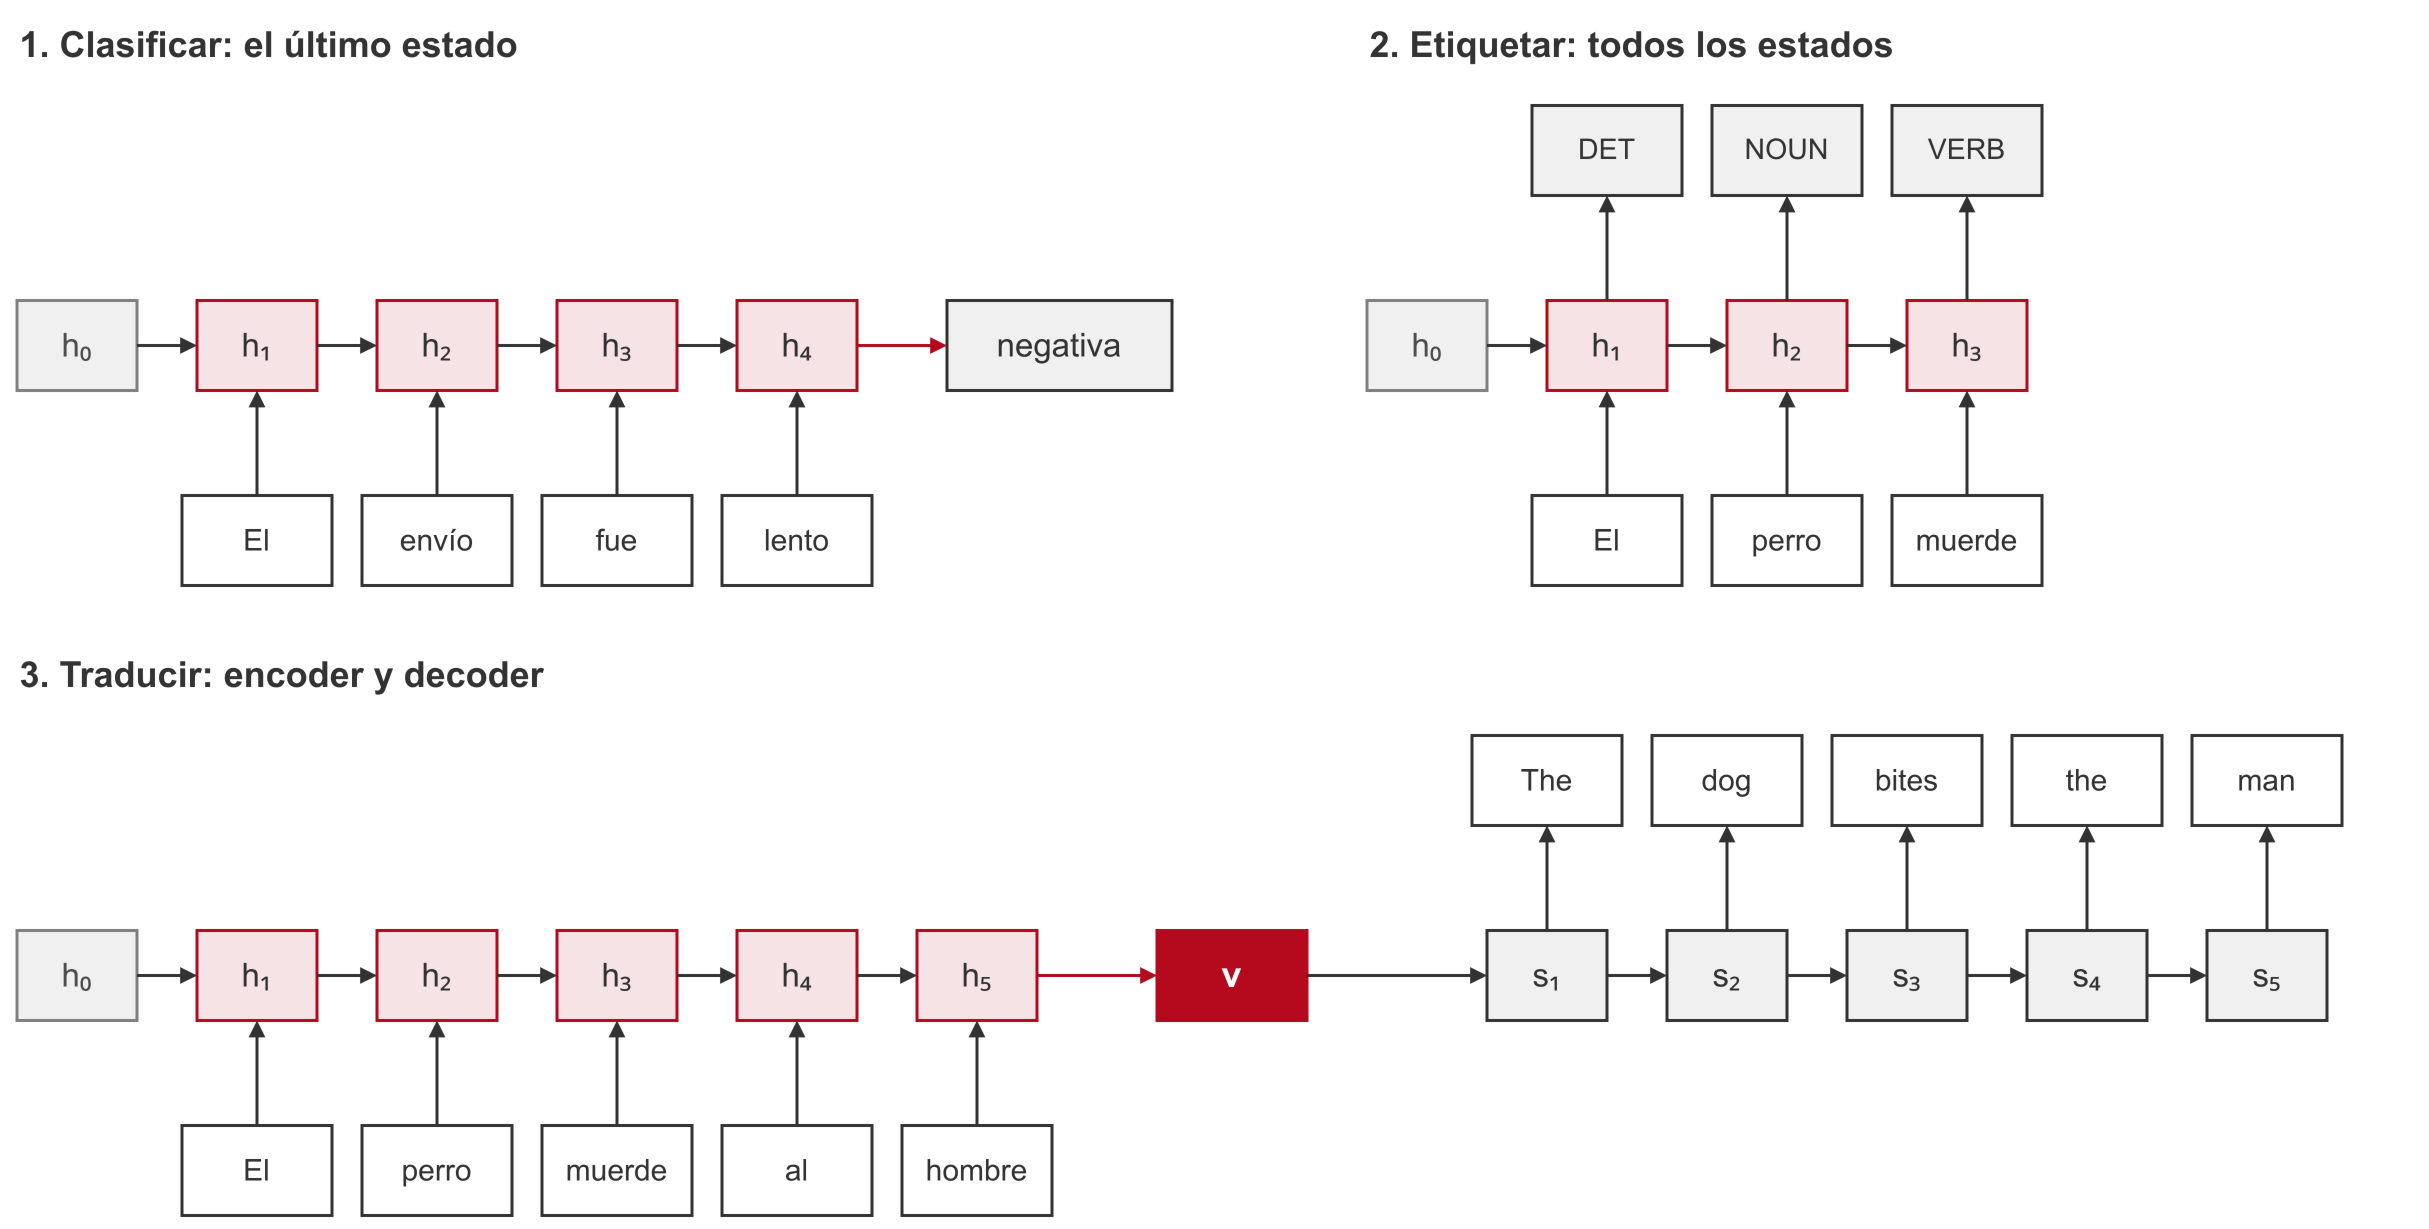

En la práctica:

| Tarea | Qué probar primero |
|---|---|
| Clasificar textos con pocos datos | TF-IDF y regresión logística, como baseline |
| Clasificar cuando el orden importa y hay datos | una GRU o LSTM; desde la clase 5, un modelo preentrenado |
| Una etiqueta por palabra (categorías, entidades) | una red bidireccional, o un modelo preentrenado |
| Texto a texto (traducir, resumir) | un encoder–decoder con atención; hoy, Transformers |
| Texto que llega de a poco (dictado, chat) o un equipo con poca memoria | una GRU o LSTM que lee hacia adelante |

## Resumen

- Una red recurrente lee una palabra por vez y guarda un estado. En la práctica se usa una GRU o una LSTM, que en PyTorch son capas como cualquier otra: `nn.GRU`, `nn.LSTM`.
- Un clasificador recurrente es embeddings → GRU → capa lineal sobre el último estado. Hay que pasarle los largos (`pack_padded_sequence`) y guardar el vocabulario junto con los pesos.
- El orden de trabajo: baseline primero, decisiones con el conjunto de validación (como la mejor epoch), el conjunto de prueba una sola vez al final y una mirada a los errores.
- Con las reseñas, la GRU empató con TF-IDF y es más grande y más lenta; con los tweets, perdió. La red se justifica cuando el orden cambia la respuesta y hay datos suficientes.
- Con todos los estados se obtiene una salida por palabra; con un encoder y un decoder, una secuencia de otro largo, limitada por el vector que pasa entre los dos.

## Para pensar

- Con las reseñas, la GRU empata con TF-IDF y tarda más. ¿En qué situación la elegirían igual?
- El traductor convierte «El hombre muerde al perro» en otra cosa. ¿Es un problema del cuello de botella, del vocabulario o de los datos de entrenamiento? ¿Cómo lo averiguarían?

## Lecturas

- Jurafsky, D. y Martin, J. H. (2026). *Speech and Language Processing* (3.ª ed., borrador del 19 de agosto de 2026), cap. 14: RNNs and LSTMs. https://web.stanford.edu/~jurafsky/slp3/
- Olah, C. (2015). Understanding LSTM networks. https://colah.github.io/posts/2015-08-Understanding-LSTMs/
- Sutskever, I., Vinyals, O. y Le, Q. V. (2014). Sequence to sequence learning with neural networks. *NeurIPS 2014*.
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H. y Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. *EMNLP 2014*, 1724–1734.
- PyTorch, documentación de `torch.nn.GRU`: https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html

## Ejercicios propuestos

Para después de la clase. Cada ejercicio supone que ya ejecutaron las celdas de preparación y la sección que se indica. Los que entrenan modelos tardan varios minutos en Colab.

### Ejercicio 1: un paso de GRU a mano

En cada paso, una GRU combina el vector de la palabra actual, $x_t$, con el estado anterior, $h_{t-1}$. Primero calcula dos compuertas, con valores entre 0 y 1 ($\sigma$ es la sigmoide):

$$z_t = \sigma(W_z x_t + U_z h_{t-1}) \qquad r_t = \sigma(W_r x_t + U_r h_{t-1})$$

Con ellas calcula el candidato y el estado nuevo ($\odot$ es el producto componente a componente):

$$\tilde h_t = \tanh\big(W x_t + r_t \odot (U h_{t-1})\big) \qquad h_t = z_t \odot h_{t-1} + (1 - z_t) \odot \tilde h_t$$

La update gate $z_t$ decide cuánto del estado anterior se conserva; la reset gate $r_t$, cuánto del estado anterior entra en el candidato. Las matrices son las mismas en todos los pasos y el estado inicial $h_0$ es un vector de ceros. Omitimos los sesgos.

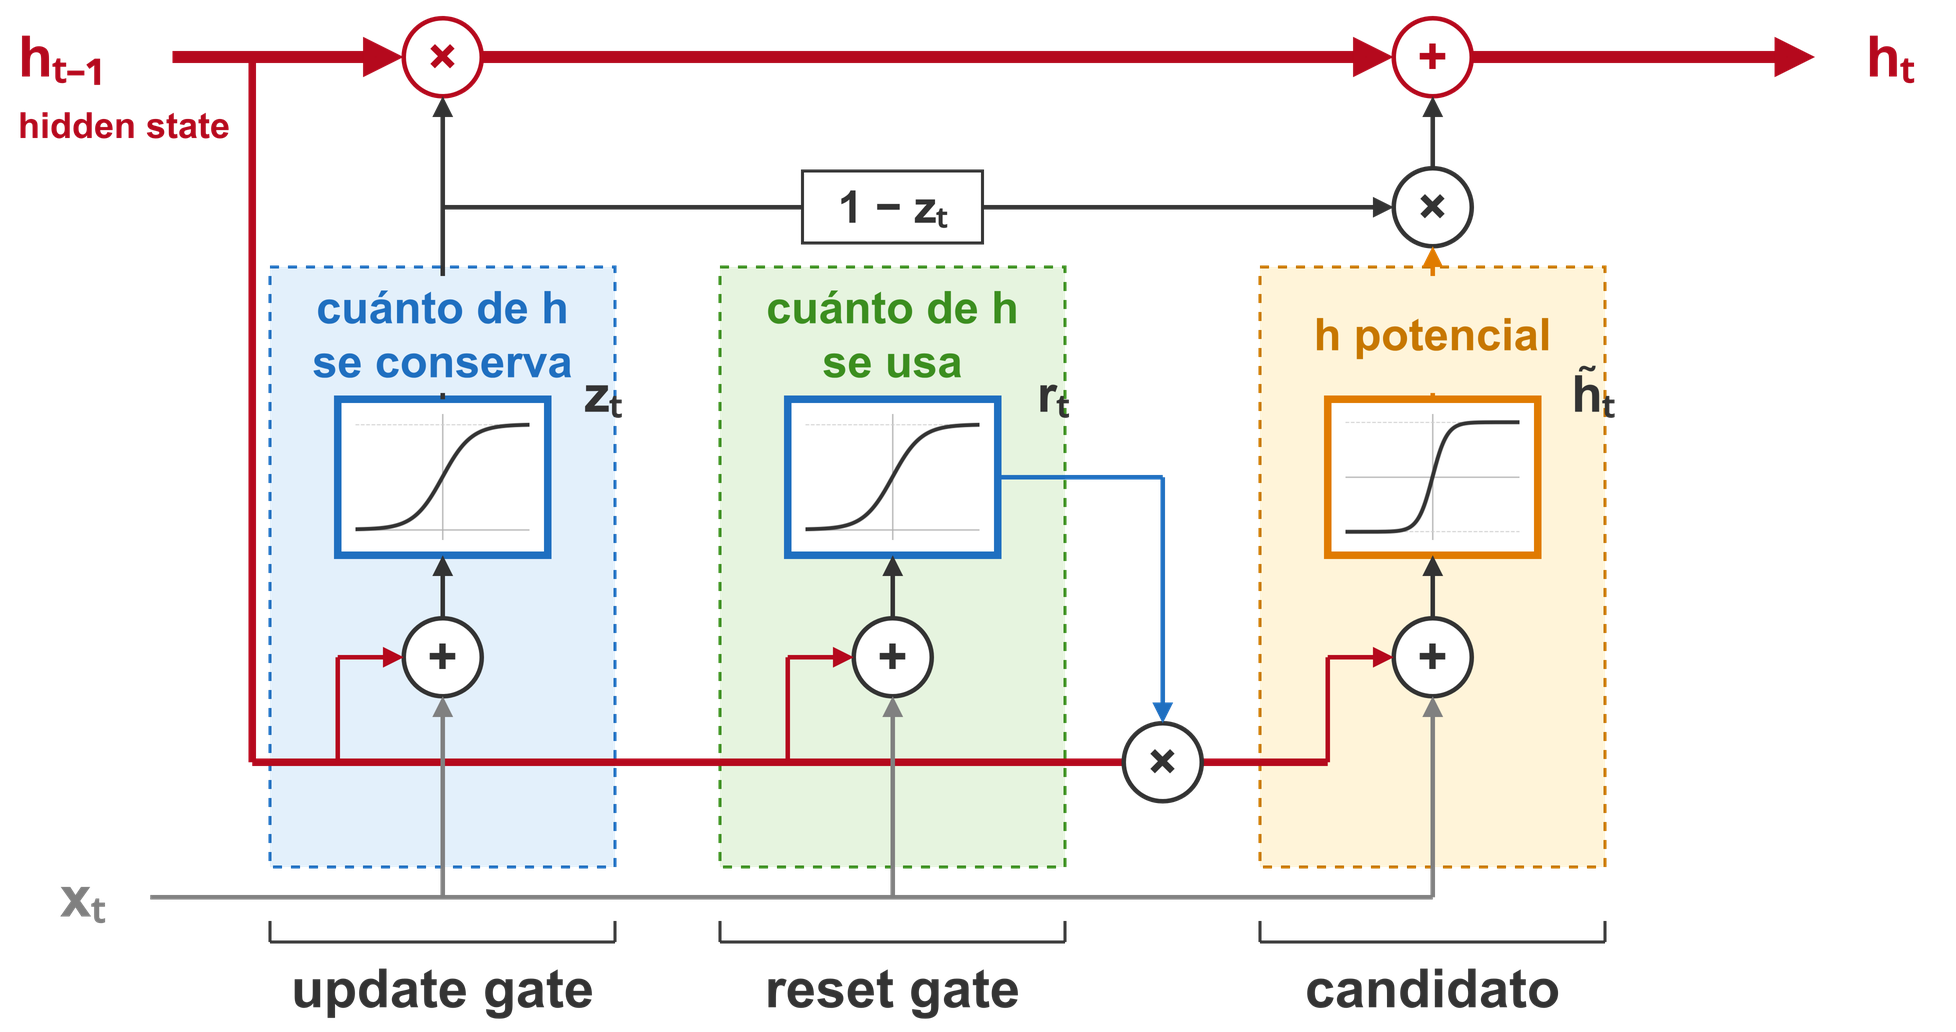

*Diagrama adaptado de Starmer (2022), «Long Short-Term Memory (LSTM), Clearly Explained», StatQuest.*

Para ver los números usamos tres palabras con vectores de dos dimensiones, inventados, y un estado también de dos dimensiones. $W$ es la identidad, así que la palabra entra tal cual al candidato. Elegimos $W_z$ para que la update gate dependa de la palabra: «perro» la deja cerca de 1 y «hombre», cerca de 0. Las matrices de la reset gate son cero, así que $r_t = 0{,}5$ en todos los pasos.

In [26]:
vectores_palabras = pd.DataFrame(
    {"perro": [1.0, 0.0],
     "muerde": [0.5, 0.5],
     "hombre": [0.0, 1.0]},
    index=["dim 1", "dim 2"], dtype="float32").T
display(vectores_palabras)

,dim 1,dim 2
perro,1.0,0.0
muerde,0.5,0.5
hombre,0.0,1.0


In [27]:
W = torch.eye(2)
U = torch.tensor([[0.5, -0.5],
                  [0.5, 0.5]])
W_z = torch.tensor([[3.0, -3.0],
                    [3.0, -3.0]])
U_z = torch.zeros(2, 2)
W_r = torch.zeros(2, 2)
U_r = torch.zeros(2, 2)


def paso(x: torch.Tensor,
         h: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Aplica un paso de la GRU.

    Parameters
    ----------
    x : torch.Tensor
        Vector de la palabra actual, forma (2,).
    h : torch.Tensor
        Estado anterior, forma (2,).

    Returns
    -------
    h_nuevo : torch.Tensor
        Estado nuevo, forma (2,).
    z : torch.Tensor
        Update gate de este paso, forma (2,).
    """
    z = torch.sigmoid(W_z @ x + U_z @ h)  # update gate
    r = torch.sigmoid(W_r @ x + U_r @ h)  # reset gate
    candidato = torch.tanh(W @ x + r * (U @ h))
    return z * h + (1 - z) * candidato, z

Leemos «perro muerde hombre» palabra por palabra. El bucle `for` es la red recurrente: la misma función `paso`, aplicada tres veces, arrastrando `h`. Mostramos también la update gate de cada paso (sus dos componentes son iguales con esta $W_z$).

In [28]:
def estados(frase: str) -> pd.DataFrame:
    """Lee la frase palabra por palabra con la GRU hecha a mano.

    Parameters
    ----------
    frase : str
        Frase con palabras de `vectores_palabras`.

    Returns
    -------
    pd.DataFrame
        Una fila por palabra con el estado y la update gate.
    """
    h = torch.zeros(2)
    palabras_frase = frase.split()
    filas = []
    for palabra in palabras_frase:
        x = torch.tensor(vectores_palabras.loc[palabra].values)
        h, z = paso(x, h)
        # las dos componentes de z son iguales, mostramos una
        filas.append(list(h.numpy()) + [z[0].item()])
    return pd.DataFrame(filas, index=palabras_frase,
                        columns=["dim 1", "dim 2", "z"])


display(estados("perro muerde hombre"))

,dim 1,dim 2,z
perro,0.04,0.00,0.95
muerde,0.25,0.23,0.50
hombre,0.02,0.78,0.05


Con «perro», $z \approx 0{,}95$: el estado casi no cambia y sigue cerca de $h_0 = 0$. Con «hombre», $z \approx 0{,}05$: el estado se reemplaza casi entero por el candidato.

**Antes de ejecutar:** si leemos «hombre muerde perro», ¿el estado final será el mismo?

In [29]:
display(estados("hombre muerde perro"))

,dim 1,dim 2,z
hombre,0.00,0.73,0.05
muerde,0.15,0.66,0.50
perro,0.18,0.64,0.95


El estado final es distinto: las mismas palabras en otro orden dejan otro estado. Además, como «perro» deja $z \approx 0{,}95$, el estado final conserva casi todo lo que había antes de leerla.

PyTorch trae esta regla en `nn.GRUCell`, que guarda las matrices de cada lado apiladas en el orden $r$, $z$, candidato. Si le copiamos las nuestras, calcula lo mismo.

In [30]:
celda = nn.GRUCell(2, 2)
with torch.no_grad():
    # PyTorch apila las matrices en el orden r, z, candidato
    celda.weight_ih.copy_(torch.cat([W_r, W_z, W]))
    celda.weight_hh.copy_(torch.cat([U_r, U_z, U]))
    celda.bias_ih.zero_()
    celda.bias_hh.zero_()

    h = torch.zeros(1, 2)
    for palabra in ["hombre", "muerde", "perro"]:
        x = torch.tensor(vectores_palabras.loc[palabra].values)
        h = celda(x[None], h)
print("Estado final de nn.GRUCell para «hombre muerde perro»:", h)

Estado final de nn.GRUCell para «hombre muerde perro»: tensor([[0.1802, 0.6372]])


Prueben: ¿qué pasa con las dos frases si $W_z$ es la matriz de ceros, de modo que $z = 0{,}5$ en todos los pasos? ¿Y si le cambian el signo?

### Ejercicio 2: los tweets de la Tarea 1

Usa las funciones de la sección 1. Comparamos la GRU con TF-IDF en los tweets, con la misma partición para los dos y con accuracy y macro-F1.

In [31]:
from sklearn.metrics import f1_score

URL_TW = ("https://raw.githubusercontent.com/dccuchile/CC6205/master/"
          "assignments/new/assignment_1/train/train.tsv")
tweets = pd.read_csv(URL_TW, sep="\t")
tweets["tokens"] = tweets["texto"].map(tokenizar)
tweets = tweets[tweets["tokens"].str.len() > 0]
clases = sorted(tweets["clase"].unique())
tweets["etiqueta"] = tweets["clase"].map(clases.index)

# misma partición para los dos modelos: 20 % prueba, 10 % del resto validación
prueba_tw = tweets.sample(frac=0.2, random_state=0)
resto_tw = tweets.drop(prueba_tw.index)
val_tw = resto_tw.sample(frac=0.1, random_state=0)
entreno_tw = resto_tw.drop(val_tw.index)
display(tweets["clase"].value_counts())

clase
incivilidad    5424
normal         4280
odio           2510
Name: count, dtype: int64

In [32]:
vocab_tw = crear_vocabulario(entreno_tw["tokens"], minimo=2)
datos_entreno_tw = lote(entreno_tw, "etiqueta", vocab_tw)
datos_val_tw = lote(val_tw, "etiqueta", vocab_tw)
torch.manual_seed(0)
modelo_tw = entrenar(Clasificador(len(vocab_tw), salidas=3),
                     datos_entreno_tw, datos_val_tw, epochs=4)

X_prueba_tw, largos_prueba_tw, etiquetas_prueba_tw = lote(
    prueba_tw, "etiqueta", vocab_tw)
with torch.no_grad():
    puntajes = modelo_tw(X_prueba_tw, largos_prueba_tw)
pred_gru = puntajes.argmax(1).numpy()

tfidf_tw = TfidfVectorizer(min_df=2)
X_entreno_tw = tfidf_tw.fit_transform(entreno_tw["texto"])
logistica_tw = LogisticRegression(max_iter=3000)
logistica_tw.fit(X_entreno_tw, entreno_tw["etiqueta"])
X_prueba_tfidf_tw = tfidf_tw.transform(prueba_tw["texto"])
pred_tfidf = logistica_tw.predict(X_prueba_tfidf_tw)

reales = etiquetas_prueba_tw.numpy()
resultados = {}
for nombre, pred in [("GRU", pred_gru), ("TF-IDF", pred_tfidf)]:
    resultados[nombre] = {
        "accuracy": (pred == reales).mean(),
        "macro-F1": f1_score(reales, pred, average="macro"),
    }
display(pd.DataFrame(resultados).T.round(3))

epoch 1: accuracy de validación 0.559


epoch 2: accuracy de validación 0.686


epoch 3: accuracy de validación 0.705


epoch 4: accuracy de validación 0.722


,accuracy,macro-F1
GRU,0.74,0.72
TF-IDF,0.77,0.75


Prueben mejorar la GRU decidiendo solo con el conjunto de validación: más epochs, un estado más grande, una LSTM o una GRU bidireccional (con `bidirectional=True`, la capa lineal recibe `torch.cat([h[-2], h[-1]], 1)`, de `2 * dim_estado` entradas). ¿Llega a TF-IDF? La Tarea 2 vuelve sobre esta comparación.